In [2]:
from pathlib import Path
import time
from os.path import join

import numpy
import pandas
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid
from IPython.display import display

import freealg
from freealg import AlgebraicForm
from freealg.distributions import FreeLevy

[(-0.8032258064516131, 0.7838709677419353), (1.1129032258064515, 3.193548387096774), (4.190322580645161, 7.6161290322580655)]


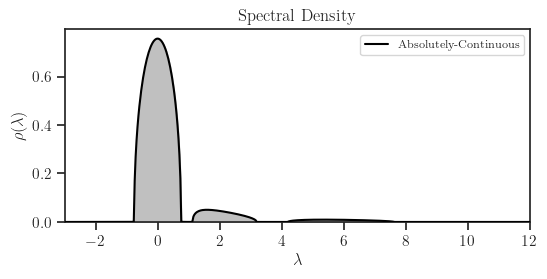

In [2]:
lam = 0.1
t1 = 2.0
t2 = 5.5
w1 = 0.75
sigma = 0.4

dist = FreeLevy(t=[t1, t2], w=[w1, 1-w1], lam=lam, a=0.0, sigma=sigma)

# Support
support = dist.support()
print(support)

# Grid
x_min = numpy.floor(min(a for a, b in support) - 1.0)
x_max = numpy.ceil(max(b for a, b in support) + 1.0)
y_min, y_max = -3.0, 3.0

_ = dist.density(plot=True, latex=True, save=False)

In [5]:
# Create data if not exists
A = dist.matrix(16000, seed=0)
eig_A = numpy.linalg.eigvalsh(A)

# As = freealg.submatrix(A, 4000, seed=0)
As = freealg.submatrix(A, 8000, seed=0)
eig_As = numpy.linalg.eigvalsh(As)

out = {
    'eig_A': eig_A,
    'eig_As': eig_As,
    'lam': lam,
    't': [t1, t2],
    'w1': w1,
    'sigma': sigma,
    'n': A.shape[0],
    'n0': As.shape[0]
}

filename = 'free-levy-abl.npz'
# dir_ = '/home/sia/work/scripts/free/Xperimental/hessian'
dir_ = '.'
out_filename = join(dir_, filename)
numpy.savez(out_filename, out=numpy.array(out, dtype=object))

In [8]:
# Load data if already created before
filename = 'free-levy-abl.npz'
# dir_ = '/home/sia/work/scripts/free/Xperimental/hessian'
dir_ = '.'
out_filename = join(dir_, filename)

data = numpy.load(out_filename, allow_pickle=True)
out = data['out'].item()

eig_A = out['eig_A']
eig_As = out['eig_As']
n = out['n']
n0 = out['n0']
decompression_ratio = n / n0

print(f'Initial size : {n0:,}')
print(f'Target size  : {n:,}')
print(f'Ratio        : {decompression_ratio:g}')

Initial size : 8,000
Target size  : 16,000
Ratio        : 2


In [9]:
# Empirically detected initial support used by AlgebraicForm
support = freealg.supp(eig_As)

print('\nDetected initial support:')
for i, interval in enumerate(support):
    print(
        f'  Interval {i + 1}: '
        f'({interval[0]:>10.6f}, {interval[1]:>10.6f})'
    )


# Known support of the exact target law
support_exact = dist.support()

print('\nExact target support:')
for i, interval in enumerate(support_exact):
    print(
        f'  Interval {i + 1}: '
        f'({interval[0]:>10.6f}, {interval[1]:>10.6f})'
    )


def padded_interval(eig, intervals, pad_fraction=0.08):
    """Construct a plotting/evaluation interval containing all supplied data."""

    left = min(
        [float(numpy.min(eig))]
        + [float(a) for a, _ in intervals]
    )
    right = max(
        [float(numpy.max(eig))]
        + [float(b) for _, b in intervals]
    )

    width = right - left

    return (
        left - pad_fraction * width,
        right + pad_fraction * width,
    )


x0_min, x0_max = padded_interval(
    eig_As,
    support,
    pad_fraction=0.08,
)

x_min, x_max = padded_interval(
    eig_A,
    support_exact,
    pad_fraction=0.08,
)


# Dense initial grid: inexpensive, because no FD evolution is involved.
n_x_initial = 2000
x_initial = numpy.linspace(
    x0_min,
    x0_max,
    n_x_initial,
)


# Final grid for reported KS and W1/L.
#
# Using 100 points is fine for a smoke test, but is too coarse for the final
# quantitative comparison across three bulks.
n_x_target = 500
x_target = numpy.linspace(
    x_min,
    x_max,
    n_x_target,
)


rho_exact = numpy.asarray(
    dist.density(x_target),
    dtype=float,
)

rho_exact = numpy.nan_to_num(
    rho_exact,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

rho_exact = numpy.maximum(rho_exact, 0.0)


exact_left = min(float(a) for a, _ in support_exact)
exact_right = max(float(b) for _, b in support_exact)
exact_width = exact_right - exact_left

print(f'\nInitial x range: ({x0_min:.6f}, {x0_max:.6f})')
print(f'Target x range : ({x_min:.6f}, {x_max:.6f})')
print(f'Exact width L  : {exact_width:.6f}')


Detected initial support:
  Interval 1: ( -0.516938,   4.306193)

Exact target support:
  Interval 1: ( -0.803226,   0.783871)
  Interval 2: (  1.112903,   3.193548)
  Interval 3: (  4.190323,   7.616129)

Initial x range: (-0.902789, 4.692044)
Target x range : (-1.476774, 8.289677)
Exact width L  : 8.419355


In [10]:
true_degree = (1, 4)

degree_pairs = [
    (1, 2),
    (1, 3),
    (1, 4),
    (1, 5),
    (1, 6),
    (2, 4),
    (4, 4),
]


# Stieltjes root-selection settings
stieltjes_opt = dict(
    n_levels=200,
    max_subdivide=20,
    anchor_mode='empirical',
    anchor_y_min=1e-4,
    anchor_y_max=1.0,
    anchor_ratio=0.01,
    anchor_match_tol=0.1,
    anchor_ratio_tol=0.9,
    anchor_retry_factor=3.0,
)


# Inverse-Stieltjes settings
inv_stieltjes_opt = dict(
    delta=1e-8,
    delta_ladder_ratio=2.0,
    delta_ladder_size=4,
    delta_ladder_grid='linear',
    z_query_delta='const',
    method='chebfit',
    fit_degree=2,
    reg=0.0,
    fit_weight='uniform',
)


# Moment constraints through degree two
mu = numpy.array(
    [
        1.0,
        numpy.mean(eig_As),
        numpy.mean(eig_As**2),
    ],
    dtype=float,
)

print('Moment constraints:')
for i, mu_i in enumerate(mu):
    print(f'  mu[{i}] = {mu_i:.12g}')


# Polynomial-fitting settings
fit_opt = dict(
    reg=0.0,
    r_min=1.8,
    r_max=2.5,
    n_r=5,
    y_scale=1.0,
    gamma=1.0,
    n_samples=4096,
    cut_eps=0.01,
    normalize=True,
    triangular=(None, None),
    mu=mu,
    mu_reg=None,
    verbose=False,
    plot=False,
)


# More conservative method-of-characteristics settings
newton_opt = dict(
    dt_max=1e-4,
    dt_min=1e-11,
    tol=1e-14,
    max_iter=500,
    parallel=True,
    n_jobs=24,
    log_mode=False,
    pair_enable=True,
    pair_gap_factor=10.0,
)


min_n_times = 100

Moment constraints:
  mu[0] = 1
  mu[1] = 0.287397743403
  mu[2] = 0.690722548957


In [11]:
def specification_label(deg_z, deg_m):
    """Label each selected degree pair relative to the known minimal pair."""

    if (deg_z, deg_m) == true_degree:
        return 'minimal exact'

    if (deg_z < true_degree[0]) or (deg_m < true_degree[1]):
        return 'under'

    return 'over'


def summarize_density(x, rho):
    """
    Return raw-mass diagnostics and a normalized nonnegative density/CDF.
    """

    x = numpy.asarray(x, dtype=float)
    rho = numpy.asarray(rho)

    rho = numpy.real_if_close(rho, tol=1000)

    if numpy.iscomplexobj(rho):
        max_imag = numpy.max(numpy.abs(rho.imag))
        raise ValueError(
            f'Density has a non-negligible imaginary part: {max_imag:.3e}.'
        )

    rho = numpy.asarray(rho.real, dtype=float).squeeze()

    if rho.shape != x.shape:
        raise ValueError(
            f'Density shape {rho.shape} does not match x shape {x.shape}.'
        )

    if not numpy.all(numpy.isfinite(rho)):
        raise ValueError('Density contains non-finite values.')

    raw_mass = numpy.trapezoid(rho, x)

    negative_part = numpy.maximum(-rho, 0.0)
    negative_mass = numpy.trapezoid(negative_part, x)

    positive_part = numpy.maximum(rho, 0.0)
    positive_mass = numpy.trapezoid(positive_part, x)

    if not numpy.isfinite(positive_mass) or positive_mass <= 0.0:
        raise ValueError('Density has no positive finite mass.')

    rho_normalized = positive_part / positive_mass

    cdf = cumulative_trapezoid(
        rho_normalized,
        x,
        initial=0.0,
    )

    if cdf[-1] <= 0.0:
        raise ValueError('Density produced a degenerate CDF.')

    cdf /= cdf[-1]

    return {
        'rho_raw': rho,
        'rho_normalized': rho_normalized,
        'cdf': cdf,
        'raw_mass': float(raw_mass),
        'positive_mass': float(positive_mass),
        'negative_mass': float(negative_mass),
    }


def compare_densities(x, rho_pred, rho_ref, spectral_width):
    """
    Compare two continuous distributions on a common x grid.

    KS is the maximum CDF discrepancy.
    W1/L is the integrated CDF discrepancy divided by spectral width.
    TV is retained internally as a strict local-shape diagnostic, but it is
    not intended for the rebuttal table.
    """

    pred = summarize_density(x, rho_pred)
    ref = summarize_density(x, rho_ref)

    cdf_difference = numpy.abs(pred['cdf'] - ref['cdf'])

    ks = numpy.max(cdf_difference)
    w1 = numpy.trapezoid(cdf_difference, x)
    w1_norm = w1 / spectral_width

    tv = 0.5 * numpy.trapezoid(
        numpy.abs(
            pred['rho_normalized']
            - ref['rho_normalized']
        ),
        x,
    )

    return {
        'pred': pred,
        'ref': ref,
        'ks': float(ks),
        'w1': float(w1),
        'w1_norm': float(w1_norm),
        'tv': float(tv),
    }


exact_summary = summarize_density(
    x_target,
    rho_exact,
)

print(f'Numerical exact-density mass: {exact_summary["raw_mass"]:.10f}')

Numerical exact-density mass: 0.9991849059


In [12]:
models = {}
rho_initial_by_degree = {}
fit_records = []


for deg_z, deg_m in degree_pairs:

    print(f'Fitting (deg_z, deg_m) = ({deg_z}, {deg_m})')

    record = {
        'deg_z': deg_z,
        'deg_m': deg_m,
        'specification': specification_label(deg_z, deg_m),
        'is_true_degree': (deg_z, deg_m) == true_degree,
    }

    try:
        af = AlgebraicForm(
            eig_As,
            support=support,
            log=False,
            dtype='complex128',
            stieltjes_opt=stieltjes_opt,
            inv_stieltjes_opt=inv_stieltjes_opt,
        )

        start = time.perf_counter()

        coeffs = af.fit(
            deg_m,
            deg_z,
            **fit_opt,
        )

        fit_time = time.perf_counter() - start

        rho_initial = af.density(
            x_initial,
            plot=False,
            latex=False,
        )

        initial_summary = summarize_density(
            x_initial,
            rho_initial,
        )

        try:
            atoms = af.atoms()
        except Exception:
            atoms = []

        atom_mass = sum(
            float(weight)
            for _, weight in atoms
        )

        models[(deg_z, deg_m)] = af
        rho_initial_by_degree[(deg_z, deg_m)] = (
            initial_summary['rho_raw']
        )

        record.update(
            {
                'fit_success': True,
                'fit_time': fit_time,
                'actual_deg_z': coeffs.shape[0] - 1,
                'actual_deg_m': coeffs.shape[1] - 1,
                'initial_mass': initial_summary['raw_mass'],
                'initial_mass_error': abs(
                    initial_summary['raw_mass'] - 1.0
                ),
                'initial_negative_mass': (
                    initial_summary['negative_mass']
                ),
                'initial_atom_mass': atom_mass,
                'error': '',
            }
        )

    except Exception as exc:

        record.update(
            {
                'fit_success': False,
                'error': f'{type(exc).__name__}: {exc}',
            }
        )

        print(f'  FAILED: {record["error"]}')

    fit_records.append(record)


fit_df = pandas.DataFrame(fit_records)

fit_display = fit_df[
    [
        'deg_z',
        'deg_m',
        'specification',
        'fit_success',
        'initial_mass_error',
        'initial_negative_mass',
        'initial_atom_mass',
        'fit_time',
        'error',
    ]
].copy()

for column in [
    'initial_mass_error',
    'initial_negative_mass',
    'initial_atom_mass',
]:
    fit_display[column] *= 100.0

display(
    fit_display.style.format(
        {
            'initial_mass_error': '{:.4f}%',
            'initial_negative_mass': '{:.4f}%',
            'initial_atom_mass': '{:.4f}%',
            'fit_time': '{:.2f}',
        },
        na_rep='---',
    )
)

Fitting (deg_z, deg_m) = (1, 2)
Fitting (deg_z, deg_m) = (1, 3)
Fitting (deg_z, deg_m) = (1, 4)
Fitting (deg_z, deg_m) = (1, 5)
Fitting (deg_z, deg_m) = (1, 6)
Fitting (deg_z, deg_m) = (2, 4)
Fitting (deg_z, deg_m) = (4, 4)


,deg_z,deg_m,specification,fit_success,initial_mass_error,initial_negative_mass,initial_atom_mass,fit_time,error
0,1,2,under,True,70.7983%,0.0000%,70.7981%,2.51,
1,1,3,under,True,0.0081%,0.0000%,0.0000%,2.39,
2,1,4,minimal exact,True,0.0039%,0.0000%,0.0000%,2.41,
3,1,5,over,True,0.0012%,0.0000%,0.0000%,2.41,
4,1,6,over,True,0.0018%,0.0000%,0.0000%,2.41,
5,2,4,over,True,0.0155%,0.0000%,0.0000%,2.41,
6,4,4,over,True,0.0029%,0.0000%,0.0000%,2.45,


In [13]:
run_coeffs_diagnostic = True

rho_moc_by_degree = {}
rho_coeffs_by_degree = {}
decompression_records = []


for deg_z, deg_m in degree_pairs:

    pair = (deg_z, deg_m)

    print(
        '\nDecompressing '
        f'(deg_z, deg_m) = ({deg_z}, {deg_m})'
    )

    record = {
        'deg_z': deg_z,
        'deg_m': deg_m,
        'specification': specification_label(deg_z, deg_m),
        'is_true_degree': pair == true_degree,
    }

    af = models.get(pair)

    if af is None:
        record.update(
            {
                'moc_success': False,
                'moc_error': 'No fitted model is available.',
            }
        )
        decompression_records.append(record)
        continue


    # ---------------------------------------------------------------
    # Optional coefficient-evolution diagnostic
    # ---------------------------------------------------------------

    if run_coeffs_diagnostic:

        try:
            start = time.perf_counter()

            rho_coeffs = af.decompress(
                n,
                x=x_target,
                kind='free',
                method='coeffs',
                atom_eps=0.0,
                return_atoms=False,
                verbose=False,
                plot=False,
            )

            coeffs_time = time.perf_counter() - start

            coeffs_comparison = compare_densities(
                x_target,
                rho_coeffs,
                rho_exact,
                spectral_width=exact_width,
            )

            rho_coeffs_by_degree[pair] = (
                coeffs_comparison['pred']['rho_raw']
            )

            record.update(
                {
                    'coeffs_success': True,
                    'coeffs_time': coeffs_time,
                    'coeffs_target_mass': (
                        coeffs_comparison['pred']['raw_mass']
                    ),
                    'coeffs_target_mass_error': abs(
                        coeffs_comparison['pred']['raw_mass'] - 1.0
                    ),
                    'coeffs_negative_mass': (
                        coeffs_comparison['pred']['negative_mass']
                    ),
                    'coeffs_ks': coeffs_comparison['ks'],
                    'coeffs_w1_norm': coeffs_comparison['w1_norm'],
                    'coeffs_tv': coeffs_comparison['tv'],
                    'coeffs_error': '',
                }
            )

        except Exception as exc:

            record.update(
                {
                    'coeffs_success': False,
                    'coeffs_error': f'{type(exc).__name__}: {exc}',
                }
            )

            print(
                '  Coefficient diagnostic failed: '
                f'{record["coeffs_error"]}'
            )


    # ---------------------------------------------------------------
    # Primary MOC decompression
    # ---------------------------------------------------------------

    try:
        start = time.perf_counter()

        rho_moc = af.decompress(
            n,
            x=x_target,
            kind='free',
            method='moc',
            min_n_times=min_n_times,
            newton_opt=dict(newton_opt),
            atom_eps=0.0,
            return_atoms=False,
            verbose=False,
            plot=False,
        )

        moc_time = time.perf_counter() - start

        moc_comparison = compare_densities(
            x_target,
            rho_moc,
            rho_exact,
            spectral_width=exact_width,
        )

        rho_moc_by_degree[pair] = (
            moc_comparison['pred']['rho_raw']
        )

        record.update(
            {
                'moc_success': True,
                'moc_time': moc_time,
                'moc_target_mass': (
                    moc_comparison['pred']['raw_mass']
                ),
                'moc_target_mass_error': abs(
                    moc_comparison['pred']['raw_mass'] - 1.0
                ),
                'moc_negative_mass': (
                    moc_comparison['pred']['negative_mass']
                ),
                'moc_ks': moc_comparison['ks'],
                'moc_w1_norm': moc_comparison['w1_norm'],
                'moc_tv': moc_comparison['tv'],
                'moc_error': '',
            }
        )

    except Exception as exc:

        record.update(
            {
                'moc_success': False,
                'moc_error': f'{type(exc).__name__}: {exc}',
            }
        )

        print(f'  MOC FAILED: {record["moc_error"]}')


    # ---------------------------------------------------------------
    # MOC-versus-coefficient diagnostic
    # ---------------------------------------------------------------

    if (
        pair in rho_moc_by_degree
        and pair in rho_coeffs_by_degree
    ):

        try:
            tracking_comparison = compare_densities(
                x_target,
                rho_moc_by_degree[pair],
                rho_coeffs_by_degree[pair],
                spectral_width=exact_width,
            )

            record.update(
                {
                    'moc_coeffs_ks': tracking_comparison['ks'],
                    'moc_coeffs_w1_norm': (
                        tracking_comparison['w1_norm']
                    ),
                    'moc_coeffs_tv': tracking_comparison['tv'],
                }
            )

        except Exception as exc:
            record['moc_coeffs_error'] = (
                f'{type(exc).__name__}: {exc}'
            )


    decompression_records.append(record)


decompression_df = pandas.DataFrame(
    decompression_records
)


Decompressing (deg_z, deg_m) = (1, 2)

Decompressing (deg_z, deg_m) = (1, 3)

Decompressing (deg_z, deg_m) = (1, 4)

Decompressing (deg_z, deg_m) = (1, 5)

Decompressing (deg_z, deg_m) = (1, 6)

Decompressing (deg_z, deg_m) = (2, 4)

Decompressing (deg_z, deg_m) = (4, 4)


In [14]:
results_df = fit_df.merge(
    decompression_df,
    on=[
        'deg_z',
        'deg_m',
        'specification',
        'is_true_degree',
    ],
    how='outer',
)


degree_order = {
    pair: i
    for i, pair in enumerate(degree_pairs)
}

results_df['_order'] = [
    degree_order.get((dz, dm), numpy.inf)
    for dz, dm in zip(
        results_df['deg_z'],
        results_df['deg_m'],
    )
]

results_df = (
    results_df
    .sort_values('_order')
    .drop(columns='_order')
    .reset_index(drop=True)
)


rebuttal_df = results_df[
    [
        'deg_z',
        'deg_m',
        'specification',
        'initial_mass_error',
        'moc_target_mass_error',
        'moc_ks',
        'moc_w1_norm',
    ]
].copy()

rebuttal_df = rebuttal_df.rename(
    columns={
        'initial_mass_error': 'initial_mass_error_pct',
        'moc_target_mass_error': 'target_mass_error_pct',
        'moc_ks': 'ks_pct',
        'moc_w1_norm': 'w1_norm_pct',
    }
)

for column in [
    'initial_mass_error_pct',
    'target_mass_error_pct',
    'ks_pct',
    'w1_norm_pct',
]:
    rebuttal_df[column] *= 100.0


display(
    rebuttal_df.style.format(
        {
            'initial_mass_error_pct': '{:.3f}%',
            'target_mass_error_pct': '{:.3f}%',
            'ks_pct': '{:.3f}%',
            'w1_norm_pct': '{:.3f}%',
        },
        na_rep='---',
    )
)

,deg_z,deg_m,specification,initial_mass_error_pct,target_mass_error_pct,ks_pct,w1_norm_pct
0,1,2,under,70.798%,85.301%,90.048%,28.493%
1,1,3,under,0.008%,0.336%,8.777%,1.634%
2,1,4,minimal exact,0.004%,0.023%,0.061%,0.009%
3,1,5,over,0.001%,0.745%,0.712%,0.196%
4,1,6,over,0.002%,0.127%,0.087%,0.023%
5,2,4,over,0.015%,0.029%,0.052%,0.015%
6,4,4,over,0.003%,0.162%,0.176%,0.029%
